In [2]:
import scipy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "scripts" / "data_cleaning.py").is_file()),
    None,
)

sys.path.insert(0, str(PROJECT_ROOT))
from scripts.data_cleaning import DATA_ROOT

df = pd.read_csv(DATA_ROOT / "AI_Usage_and_Impact_on_Students_and_Professionals_cleaned.csv")

df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30.0,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,chatgpt,Office Work,2.0,Data analysis using AI-powered analytics tools...,0.0,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30.0,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,chatgpt,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.4,8.4,Yes
2,U0152,17.0,Male,Canada,Student,Bachelor's,Computer Science Student,402.0,chat gpt,Coding,1.0,"Debugging code with AI assistance, generating ...",20.0,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35.0,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367.0,meta ai,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19.0,Female,Canada,Student,Undergraduate,Biology Student,438.0,perplexity ai,Coding,4.1,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.2,6.2,Yes


In [3]:
df["Gender"] = df["Gender"].str.lower()
df["AI_Tool"] = (
    df["AI_Tool"]
    .str.replace(" ", "_", regex=False)
    .str.lower()
    .replace("chatgpt", "chat_gpt")
)

### Question number 1

Is AI use associated with greater utility?

For this purpose I can build a Linear regresiion if the relationships betweenn these two features follows a linear trend

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = df[['AI_Usage_Hours_Per_Day']]
y = df[['Time_Saved_Hours_Per_Week']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
predictions = model.predict(X_test)

# --- EVALUATION --- #
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print(f"R^2 Score: {r2}\nMean Absolute Error: {mae}\nMean Squared Error:{mse}")

R^2 Score: 0.6251522085130101
Mean Absolute Error: 1.708681038345392
Mean Squared Error:4.990286024862131


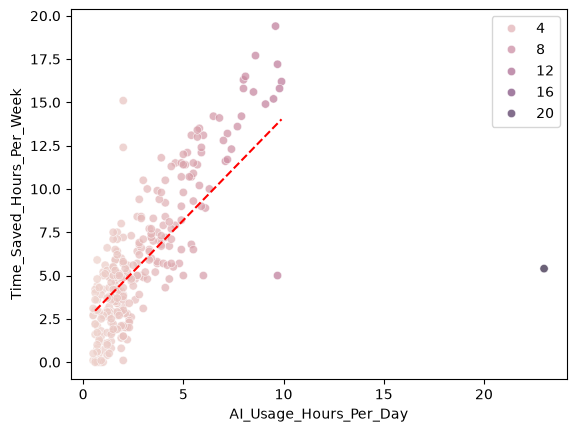

In [5]:
# scatter plot of actual data
sns.scatterplot(data=df, x="AI_Usage_Hours_Per_Day", y="Time_Saved_Hours_Per_Week", hue="AI_Usage_Hours_Per_Day", alpha=0.7)
# build a dataframe for the fitted regression line
x_line = X_test.sort_values("AI_Usage_Hours_Per_Day")["AI_Usage_Hours_Per_Day"]
y_line = model.predict(x_line.to_frame()).ravel()
line_df = pd.DataFrame({"AI_Usage_Hours_Per_Day": x_line,"Time_Saved_Hours_Per_Week": y_line})
# regression line
sns.lineplot(data=line_df,x="AI_Usage_Hours_Per_Day",y="Time_Saved_Hours_Per_Week",linewidth=1.5,linestyle="--",color="red")

plt.show()

Positive Linear Relationship between the two variables, which gives an idea about their relationship

We can conduct T test to make sure that the variable has predictive value

In [6]:
def t_test(model: LinearRegression) -> list:
    X_values = np.asarray(X_train)
    y_values = np.asarray(y_train)

    if y_values.ndim == 1:
        y_values = y_values.reshape(-1, 1)

    predictions = np.asarray(model.predict(X_train))
    if predictions.ndim == 1:
        predictions = predictions.reshape(-1, 1)

    design = (
        np.column_stack([np.ones(len(X_values)), X_values])
        if model.fit_intercept
        else X_values
    )
    degrees_freedom = len(y_values) - np.linalg.matrix_rank(design)
    if degrees_freedom <= 0:
        raise ValueError("Not enough residual degrees of freedom for t-tests.")

    covariance_base = np.linalg.pinv(design.T @ design)
    coefficients = np.atleast_2d(model.coef_)
    intercepts = np.atleast_1d(model.intercept_)

    feature_names = list(getattr(
        X_train, "columns", [f"x{i}" for i in range(X_values.shape[1])]
    ))

    if model.fit_intercept:
        parameters = np.column_stack([intercepts, coefficients])
        names = ["intercept", *feature_names]
    else:
        parameters = coefficients
        names = feature_names

    results = []
    residuals_by_output = (y_values - predictions).T

    for output_idx, residuals in enumerate(residuals_by_output):
        residual_variance = (residuals @ residuals) / degrees_freedom
        standard_errors = np.sqrt(np.diag(covariance_base) * residual_variance)

        for name, coefficient, standard_error in zip(
            names, parameters[output_idx], standard_errors
        ):
            t_stat = coefficient / standard_error
            p_value = 2 * scipy.stats.t.sf(abs(t_stat), degrees_freedom)
            results.append({
                "term": name,
                "coefficient": coefficient,
                "t_stat": t_stat,
                "p_value": p_value,
            })

    return results

print(t_test(model))

[{'term': 'intercept', 'coefficient': np.float64(2.2513711315649827), 't_stat': np.float64(7.793687232538425), 'p_value': np.float64(2.2945559622625205e-13)}, {'term': 'AI_Usage_Hours_Per_Day', 'coefficient': np.float64(1.1888287097220975), 't_stat': np.float64(16.005080494342003), 'p_value': np.float64(3.755264634882323e-39)}]


We can safely reject the  null hypothesis since t-value is bigger than 1.96, with a 95% confidence

### Question number 2

Do students and professionals report different outcomes?

In [9]:
# isolate students and professionals into a separate datframe
student_and_pro = df[df["User_Type"].isin(['Professional', 'Student'])]

student_and_pro

# now conduct another hypothesis test
# Convert daily usage to weekly usage, then calculate time saved per usage hour.
comparison = student_and_pro.copy()
weekly_usage = comparison["AI_Usage_Hours_Per_Day"] * 7
comparison["Time_Saved_Per_Usage_Hour"] = (
    comparison["Time_Saved_Hours_Per_Week"] / weekly_usage
)

student_values = comparison.loc[
    comparison["User_Type"] == "Student", "Time_Saved_Per_Usage_Hour"
].replace([np.inf, -np.inf], np.nan).dropna()

professional_values = comparison.loc[
    comparison["User_Type"] == "Professional", "Time_Saved_Per_Usage_Hour"
].replace([np.inf, -np.inf], np.nan).dropna()

# Welch's two-sample t-test; H0: the group means are equal.
test_result = scipy.stats.ttest_ind(
    student_values, professional_values, equal_var=False
)

print(f"Student mean: {student_values.mean():.3f}")
print(f"Professional mean: {professional_values.mean():.3f}")
print(f"t-statistic: {test_result.statistic:.3f}")
print(f"p-value: {test_result.pvalue:.4f}")

Student mean: 0.317
Professional mean: 0.333
t-statistic: -0.662
p-value: 0.5083


Verdict. It does not matter whether you are a Professional or a Student MAJORITY of the time.

In [8]:
# we may even increase the Confidence interval to prove that the alternative hypothesis is wrong
alpha = 0.01
mean_difference = student_values.mean() - professional_values.mean()

standard_error = np.sqrt(
    student_values.var(ddof=1) / len(student_values)
    + professional_values.var(ddof=1) / len(professional_values)
)

critical_value = scipy.stats.t.ppf(1 - alpha / 2, df=test_result.df)
ci_lower = mean_difference - critical_value * standard_error
ci_upper = mean_difference + critical_value * standard_error

print(f"Mean difference (Student - Professional): {mean_difference:.3f}")
print(f"99% confidence interval: [{ci_lower:.3f}, {ci_upper:.3f}]")
print(f"p-value: {test_result.pvalue:.4f}")

if ci_lower <= 0 <= ci_upper:
    print("The interval includes zero: fail to reject the equal-means null hypothesis at α = 0.01.")
else:
    print("The interval excludes zero: reject the equal-means null hypothesis at α = 0.01.")

Mean difference (Student - Professional): -0.016
99% confidence interval: [-0.076, 0.045]
p-value: 0.5083
The interval includes zero: fail to reject the equal-means null hypothesis at α = 0.01.


Whitney U test

In [10]:
# H0: the two groups have the same distribution.
# H1: their distributions differ.
u_statistic, p_value = scipy.stats.mannwhitneyu(
    student_values,
    professional_values,
    alternative="two-sided"
)

print(f"Student median: {student_values.median():.3f}")
print(f"Professional median: {professional_values.median():.3f}")
print(f"Mann–Whitney U statistic: {u_statistic:.3f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Reject the null hypothesis at α = 0.05; the groups differ.")
else:
    print("Fail to reject the null hypothesis at α = 0.05; there is insufficient evidence of a difference.")

Student median: 0.283
Professional median: 0.302
Mann–Whitney U statistic: 9957.500
p-value: 0.5850
Fail to reject the null hypothesis at α = 0.05; there is insufficient evidence of a difference.
